In [1]:
import json
import os
import cv2
import json
import shutil
import pyewts
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from glob import glob
from pathlib import Path
from evaluate import load
from natsort import natsorted
from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OCRInference, KerasInference
from IPython.display import Image as ShowImage
from Exporter import PageXMLExporter
from Utils import create_dir, get_line_images_from_line_data, rotate_from_angle, get_random_color, read_lines_from_file, get_file_name, get_lines_from_page

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def show_image(image: np.array, cmap: str = "") -> None:
    plt.figure(figsize=(24, 13))
    #plt.axis("off")
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

def show_overlay(image: np.array, mask: np.array, alpha=0.4):
    plt.figure(figsize=(18, 9))
    plt.axis("off")
    plt.imshow(image)
    plt.imshow(mask, alpha=alpha)

In [3]:
converter = pyewts.pyewts()
cer_scorer = load("cer")

layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

In [13]:
keras_model_config = "Models/OCRModels/LhasaKanjurEaster/v2/model_config.json"
keras_inf = KerasInference(keras_model_config)

Loading Easter2
Y_pred: KerasTensor(type_spec=TensorSpec(shape=(None, 500, 73), dtype=tf.float32, name=None), name='Final/Softmax:0', description="created by layer 'Final'")


In [4]:
data_path = "D:/Datasets/Tibetan/LhasaKanjur"

images = natsorted(glob(f"{data_path}/pages/*.jpg"))
label_paths = natsorted(glob(f"{data_path}/transcriptions/*.txt"))

print(f"Images: {len(images)}, Transcriptions: {len(label_paths)}")

rare_stack_file = "D:/Datasets/Tibetan/LhasaKanjur/rare_stack_pages_lhasa.txt"
rage_stack_pages = read_lines_from_file(rare_stack_file)

Images: 94160, Transcriptions: 94160


In [5]:
rage_stack_pages =  [x.replace("\n", "") for x in rage_stack_pages]
rage_stack_pages[0]

'90-1-212b'

In [6]:
rare_stack_labels = [f"{data_path}/transcriptions\\{x}.txt" for x in rage_stack_pages]
print(rare_stack_labels[0])

D:/Datasets/Tibetan/LhasaKanjur/transcriptions\90-1-212b.txt


87251
D:/Datasets/Tibetan/LhasaKanjur/transcriptions\92-1-239b.txt
བ་རེ་ཧཱུཾ། ཨོཾ་ཤྲཱི་བོ་དྷ་ཡ་ཧཱུཾ། ཨོཾ་བི་ཛ་ཡ་པུརྞ་བ་རེ་ཧཱུཾ། ཨོཾ་ཕ་ལོད་བྷེ་བེ་ཏུ་རེ་ཧཱུཾ། ཨོཾ་པཱུརྞ་མཎྜ་ལེ་ཛ་ཡ་ཧཱུཾ། ཨོཾ་ས་ཧ་སྲ་རཤྨི་ཀི་ར་ཎེ་ཧཱུཾ། ཨོཾ་སརྦ་དུཥྚན་པྲ་ཧ་ར་ཤཱ་སཱ་ཡ་ཧཱུཾ། ཨོཾ་
མ་ན་བི་ཤོ་དྷ་ཡ་མཱ་ལཱ་བི་མ་ལེ་ཧཱུཾ། ཨོཾ་པུཥྤ་བ་ཏི་སུ་གནྡྷ་བ་རེ་ཧཱུཾ། ཨོཾ་པཱ་ཤ་ས་ཧ་སྲ་གུ་ཎི་ཏེ་ཀྵ་ཎ་ཀྵ་ཎ་ཧཱུཾ། ཨོཾ་བཛྲོད་ཀྵེ་པ་སུ་ཙི་མུ་ཁ་ཙི་ཊི་ཙི་ཊི་ཧཱུཾ། ཨོཾ་ཨ་མོ་གྷ་ཨ་པྲ་ཏི་ཧ་ཏ་པཱ་
ཤ་ཧ་སྟེ་ཧཱུཾ། ཨོཾ་སརྦ་ཏྲ་ཨ་མོ་གྷ་སིདྡྷ་སིདྡྷྱ་སཱ་དྷ་ཡ་ཧཱུཾ། ལག་པའི་ཕྱག་རྒྱ་འདི་དག་དག། །དེ་བཞིན་གསང་སྔགས་ཕྱག་རྒྱ་དང་།ལྷན་ཅིག་བཟླས་པ་ཙམ་དང་ནི། །ཕྱག་རྒྱ་མཐོང་
བ་ཁོ་ནས་ཀྱང༌། །སྡིག་པ་ཐམས་ཅད་མོད་ལ་འཇོམས། །མྱུར་དུ་སངས་རྒྱས་ཉིད་འཐོབ་འགྱུར། །ཆོ་ག་ཞིབ་མོ་མྱུར་དུ་འགྲུབ། །དོན་ཡོད་ཞགས་པ་རྣམ་གྲོལ་བའི། །དཀྱིལ་འཁོར་
དམ་པ་འགྲུབ་པར་འགྱུར། །དེ་ལ་མཚོན་ཆའི་ཕྱག་རྒྱ་ནི། ནོར་བུ་རིན་པོ་ཆེ་དང༌། མེ་ཏོག་དང༌། པདྨ་དང༌། རིལ་བ་སྤྱི་བླུགས་དང༌། ནོར་བུའི་ཕྲེང་བ་དང༌། བགྲང་ཕྲེང་བ་དང༌། དུང་
དང༌། འཁོར་ལོ་དང༌། དབྱུག་ཐོ་དང༌། མདུང་ཐུང་དང༌། རྡོ་རྗེ་དང༌། རྩེ་གསུམ་དང༌། རྩེ་གསུམ་ཁ་གདེངས་དང༌། མཚོན་ཤཀྟི་དང༌། རྡོ་རྗེ་

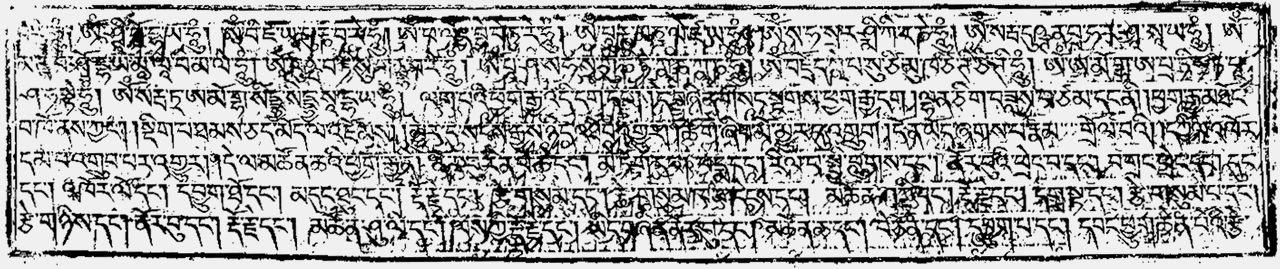

In [8]:
r_idx = 123
r_lbl = rare_stack_labels[123]
idx = label_paths.index(r_lbl)
print(idx)
print(label_paths[idx])
ref_label = get_lines_from_page(label_paths[idx])

for lbl in ref_label:
    print(lbl)

ShowImage(images[idx])


(269, 1280, 3)


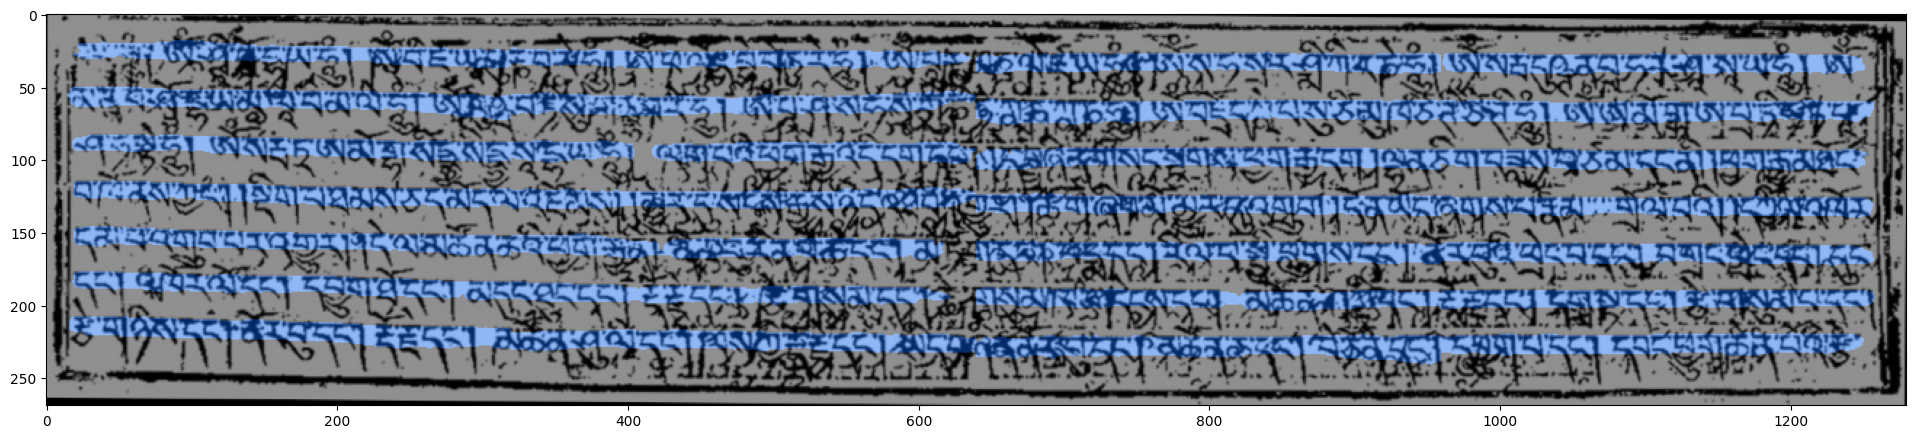

In [9]:
try:
  image_name = os.path.basename(images[idx]).split(".")[0]
  _img = cv2.imread(images[idx])

  print(_img.shape)

except FileExistsError as e:
    print.error(f"Cant read file at provided location: {images[idx]}, {e}")

# layout_inference
layout_data, preview_img = layout_inference.predict(_img)

show_image(preview_img)

In [47]:
preview_img.shape

(269, 1280, 3)

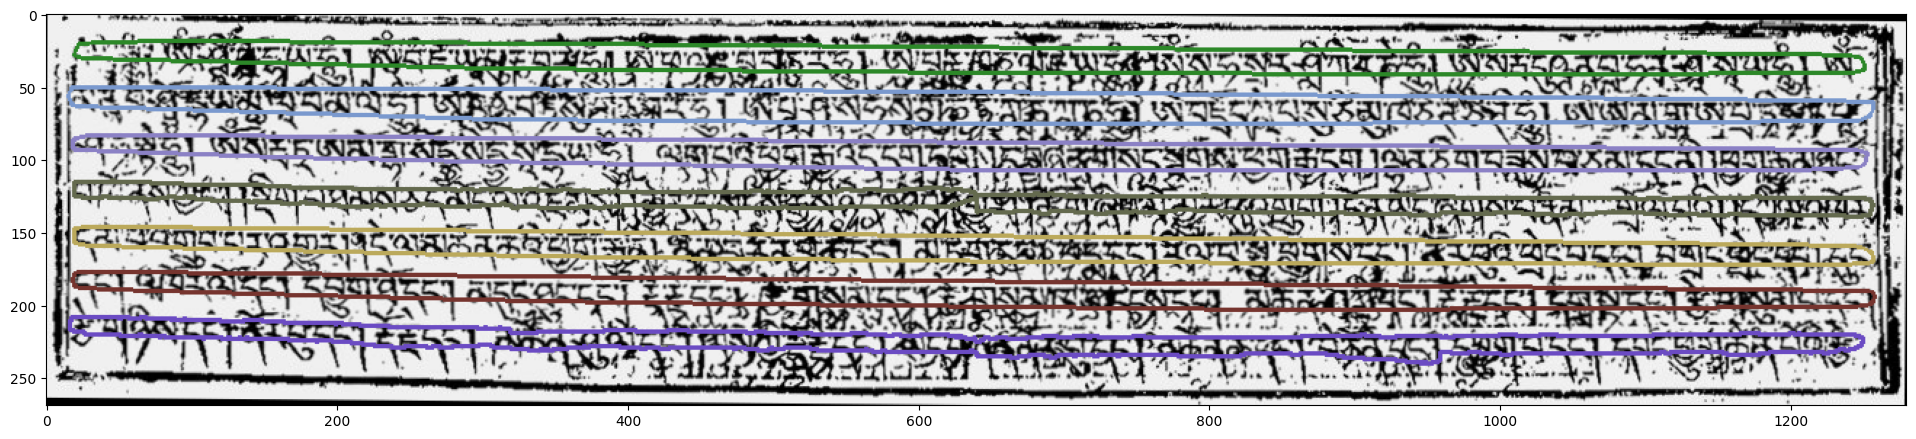

In [10]:
sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=False)
r_img = rotate_from_angle(_img, layout_data.rotation)
prev_img = r_img.copy()
color = get_random_color()

for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

In [11]:
layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=14, calculate_iterations=False)

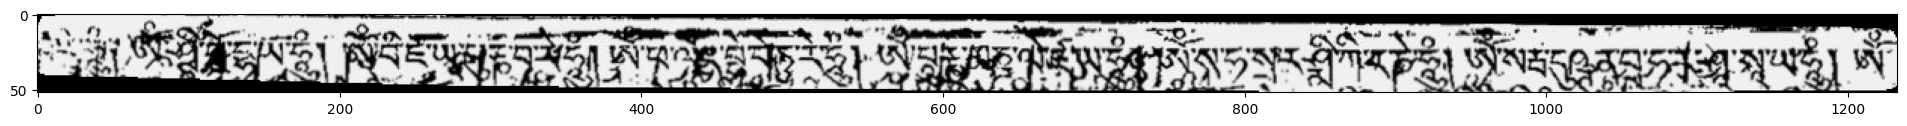

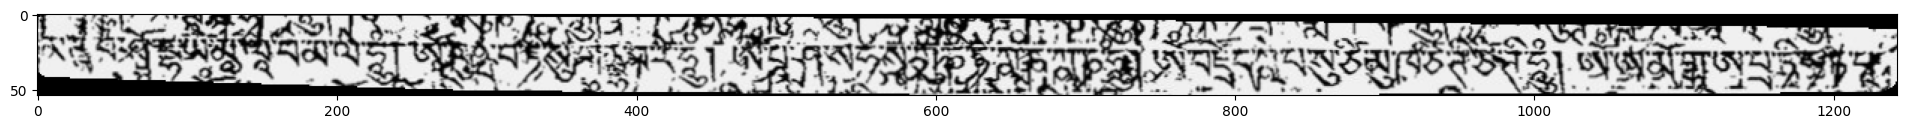

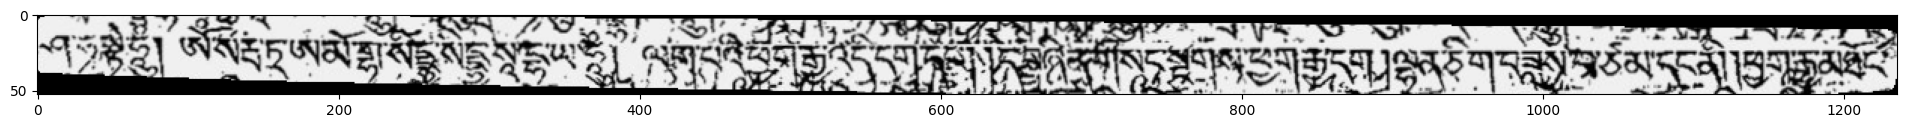

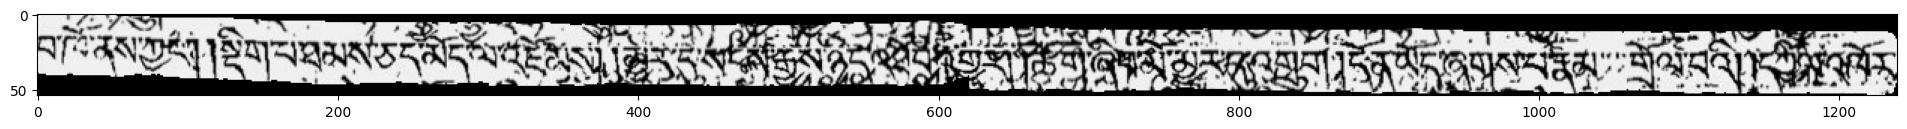

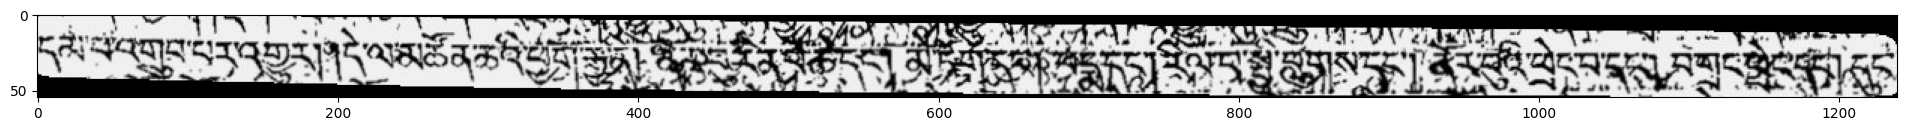

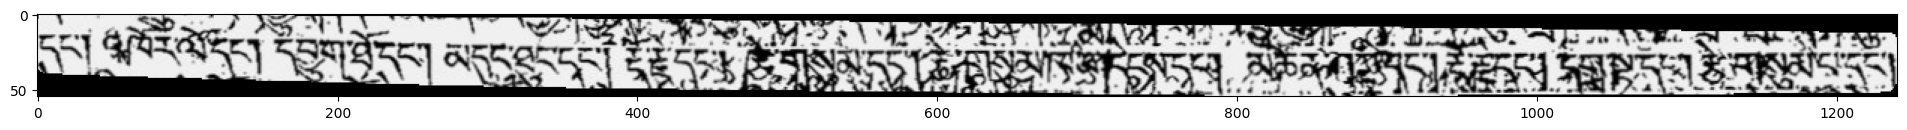

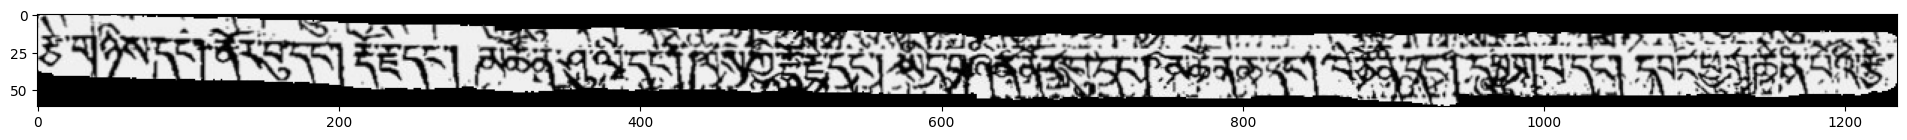

In [12]:
for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])

In [14]:
ocr_prediction = keras_inf.run(layout_line_images)

for line in ocr_prediction:
    print(line)

3
(7, 2000, 80)
ཟུ། ལཾ་བྱཱུཾ་+ཨ་དྷ་ཡ་དཱུཾ། །སཾ་ཟ་རྫམུ་རྫཏམ་ཨ། ཐབ་བད་སྦྱ་ནཏུར་གྱ། ཏོ་དདན་ཟད་དདསྦགན་སྒའི་རྙི་ཨིཨ་ཨ་ཨི། རཅི
མན་བ་སོཾ་དྷ་ཡི་མ་ལ་བ་མ་ལ་བཱུཾ། ཨཾ་དན་བ་ཏེ་སུ་མརབར་མ་ཤསས་ག་བ་རོ་ས་འདྱོ་སས་འ་སྣ་ཨི་
ཧ་སྟེ་ཧཱུཾ། ཨོཾ་སར་ད་ཨ་མོ་གྱ་སིནྡ་སི་ནྷ་སཱ་དྷ་ཡ་ཏཱུཾ། ལག་པའཕྱག་སྒྱུན་དི་དག་པབནི་ད་ག་འ་ཨི་རན་ཨ་ད་བི་ད་སནན་བཱུཾ་བ
བ་ཁོ་ནས་ཀྱང་། །སྡིག་པ་ཐམས་ཅད་མེད་པས་རྡོམས་ཨི་སྒྱན་དིའམིནད་ས་བན་ཡ་ན་ག་དེན་དཅིའ་ཨིའ་ག་ད་དནི་ར་ན་སྒ་ཨ་གིདད
དམ་པ་འགྲུབ་པར་འགྱུར། །དེ་ལ་མཚོན་ཆའི་བྱསག་སནའ་བཅུར་དབ་སྒ་འོན་ཨི་ལྐི་སི་ན་བིདགི་ཨ་
དང་། འཁོར་ལོ་དང་། དབྱུག་ཐོ་དང་། མདུང་བྱུང་དང། ཨརད་ཅོཨབ་མ་སགས་ཨི་ཡོན་ཆུ་སད་སྤན་ཅ་སསག་ཡིད་སས་བི་
གཉིས་དང་། ནོར་བུ་དང་། རྡོ་རྗེ་དང་། མཚོན་ཤས་དག་པར་བད་ཨི་ཅིན་གྱད་པ་བ་དག་བ་ད་ཐོ་དདི་དའ་བྱིན་རད་ཏན་གྱ


#### Run on All Images:


In [7]:
dataset_output = os.path.join(data_path, "RareStackDataset")
xml_out = os.path.join(dataset_output, "page")

create_dir(dataset_output)
create_dir(xml_out)

xml_exporter = PageXMLExporter(xml_out)

In [8]:
mismatch_pages = []

for idx, r_label_file in tqdm(enumerate(rare_stack_labels), total=len(rare_stack_labels)):
    idx = label_paths.index(r_label_file)
    ref_label = get_lines_from_page(label_paths[idx])

    try:
        image_name = os.path.basename(images[idx]).split(".")[0]
        _img = cv2.imread(images[idx])

    except FileExistsError as e:
        print.error(f"Cant read file at provided location: {images[idx]}, {e}")

    # layout_inference
    layout_data, _ = layout_inference.predict(_img)
    sorted_layout_data = layout_inference.sort_lines(layout_data, threshold=20, calculate=False)
    r_img = rotate_from_angle(_img, layout_data.rotation)

    layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=14, calculate_iterations=False)


    if len(ref_label) == len(layout_line_images):
        img_out = f"{dataset_output}/{image_name}.jpg"
        cv2.imwrite(img_out, r_img)
        xml_exporter.export(r_img, image_name, sorted_layout_data, ref_label)

    else:
        mismatch_pages.append(image_name)

print(f"Mismatched pages: {len(mismatch_pages)}")

mismatch_pages_out = f"{data_path}/rare_stack_page_mapping_mismatches.txt"

with open(mismatch_pages_out, "w", encoding="utf-8") as f:
    for p in mismatch_pages:
        f.write(f"{p}\n")

    

  0%|          | 0/10205 [00:00<?, ?it/s]

100%|██████████| 10205/10205 [5:06:34<00:00,  1.80s/it] 

Mismatched pages: 569
